In [42]:
import numpy as np
import urllib.request
import gzip

#Claude Generated code to import the damn dataset


def load_mnist():
    base_url = "https://storage.googleapis.com/cvdf-datasets/mnist/"
    files = {
        "train_images": "train-images-idx3-ubyte.gz",
        "train_labels": "train-labels-idx1-ubyte.gz",
        "test_images":  "t10k-images-idx3-ubyte.gz",
        "test_labels":  "t10k-labels-idx1-ubyte.gz",
    }

    data = {}
    for key, fname in files.items():
        urllib.request.urlretrieve(base_url + fname, fname)
        with gzip.open(fname, 'rb') as f:
            raw = np.frombuffer(f.read(), dtype=np.uint8)
            if "images" in key:
                data[key] = raw[16:].reshape(-1, 784)   # skip 16-byte header
            else:
                data[key] = raw[8:]                      # skip 8-byte header

    return data

data = load_mnist()
X_train = data["train_images"] / 255.0   # normalize to [0, 1]
y_train = data["train_labels"]
X_test  = data["test_images"]  / 255.0
y_test  = data["test_labels"]

X_train = np.transpose(X_train)
X_test = np.transpose(X_test)

def one_hot(y, classes=10):
    Y = np.zeros((classes, len(y)))
    Y[y, np.arange(len(y))] = 1
    return Y
Y_train = one_hot(y_train)   # (10, 60000)
Y_test = one_hot(y_test)     # (10, 10000)

In [43]:
np.shape(X_train)

(784, 60000)

In [44]:
#NumPy to generate Wx+B ig
#Initialization.

W = np.random.randn(10, 784) * 0.01
b = np.zeros((10, 1))
lr = 0.1

In [45]:
def cross_entropy_loss(Y, A):
    # Y is one-hot encoded (10, 60000)
    # A is softmax output  (10, 60000)
    return -np.mean(np.sum(Y * np.log(A), axis=0), keepdims = True)

def softmax(Z):
    expZ = np.exp(Z - np.max(Z, axis=0, keepdims=True))
    return expZ / np.sum(expZ, axis=0, keepdims=True)

In [50]:
losses = []
accuracies = []
for iterations in range(1000):
  Z = W @ X_train + b
  A = softmax(Z)
  #Backprop

  loss = cross_entropy_loss(Y_train, A)
  losses.append(loss)
  print(iterations, loss)
  preds = np.argmax(A, axis=0)
  acc = np.mean(preds == y_train)
  accuracies.append(acc)
  dZ = A - Y_train
  dW = (1/60000) * dZ @ X_train.T
  db = (1/60000) * np.sum(dZ, axis=1, keepdims=True)


  #update
  W = W - lr * dW
  b = b - lr * db

0 [0.34696405]
1 [0.34690864]
2 [0.34685331]
3 [0.34679807]
4 [0.3467429]
5 [0.34668782]
6 [0.34663282]
7 [0.3465779]
8 [0.34652306]
9 [0.3464683]
10 [0.34641362]
11 [0.34635902]
12 [0.3463045]
13 [0.34625007]
14 [0.34619571]
15 [0.34614143]
16 [0.34608723]
17 [0.34603311]
18 [0.34597907]
19 [0.34592511]
20 [0.34587123]
21 [0.34581742]
22 [0.3457637]
23 [0.34571005]
24 [0.34565648]
25 [0.34560298]
26 [0.34554957]
27 [0.34549623]
28 [0.34544297]
29 [0.34538978]
30 [0.34533667]
31 [0.34528364]
32 [0.34523069]
33 [0.34517781]
34 [0.345125]
35 [0.34507228]
36 [0.34501963]
37 [0.34496705]
38 [0.34491455]
39 [0.34486212]
40 [0.34480977]
41 [0.34475749]
42 [0.34470529]
43 [0.34465316]
44 [0.34460111]
45 [0.34454913]
46 [0.34449722]
47 [0.34444539]
48 [0.34439363]
49 [0.34434195]
50 [0.34429033]
51 [0.34423879]
52 [0.34418732]
53 [0.34413593]
54 [0.34408461]
55 [0.34403336]
56 [0.34398218]
57 [0.34393107]
58 [0.34388004]
59 [0.34382907]
60 [0.34377818]
61 [0.34372736]
62 [0.34367661]
63 [0.343

KeyboardInterrupt: 

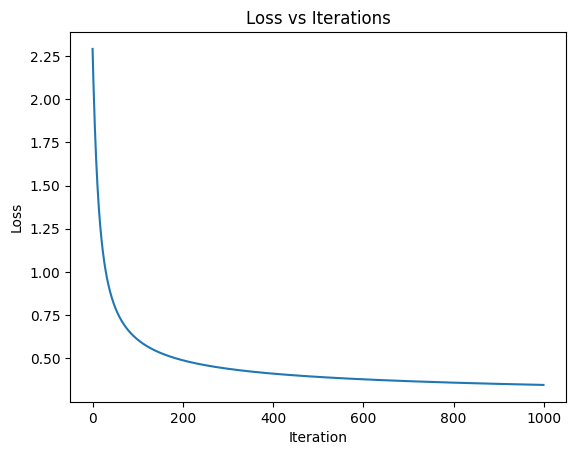

Test Accuracy: 90.95%


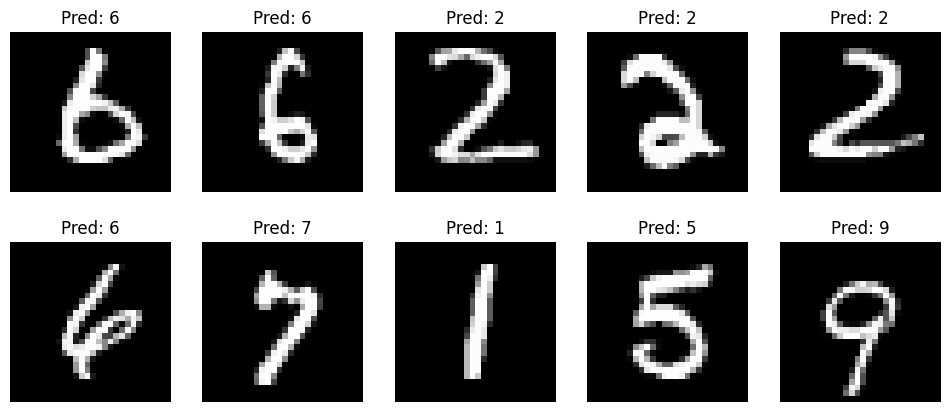

In [47]:
import matplotlib.pyplot as plt

# Plot loss curve
plt.plot(losses)
plt.xlabel("Iteration")
plt.ylabel("Loss")
plt.title("Loss vs Iterations")
plt.show()

# Evaluate on test set
Z_test = W @ X_test + b
A_test = softmax(Z_test)
predictions = np.argmax(A_test, axis=0)
accuracy = np.mean(predictions == y_test)
print(f"Test Accuracy: {accuracy*100:.2f}%")

# Qualitative snapshots
fig, axes = plt.subplots(2, 5, figsize=(12, 5))
for i, ax in enumerate(axes.flat):
    idx = np.random.randint(0, X_test.shape[1])
    ax.imshow(X_test[:, idx].reshape(28, 28), cmap='gray')
    ax.set_title(f"Pred: {predictions[idx]}")
    ax.axis('off')
plt.show()